# EDA · Kenya · perinatal (headline cohort)

Dataset: `data/processed/ke_perinatal.csv`.
Outcome: `perinatal_death` (stillbirth or death in the first 7 days).

Base predictors only. This is the main cohort for the headline result.

What this notebook should cover:
- shape and dtypes; confirm the row count matches the proposal
- missingness (expect blanks in told_high_bp, preceding_interval_m)
- the outcome rate
- distributions of the predictors (maternal_age, prior_pregnancies, prior_live_births, prior_stillbirth, prior_loss, preceding_interval_m, multiple, education, wealth_quintile, residence, region, told_high_bp) and the outcome rate within each category

Clear outputs before committing.


In [9]:
import pandas as pd
import numpy as np

from pathlib import Path

# Load the CSV file into a DataFrame
df = pd.read_csv("ke_perinatal.csv")

# Display the first five rows
df.head()

,caseid,v001,v005,v011,v022,v024,v025,v106,v190,pidx,...,preceding_interval_m,weight,told_high_bp,education,wealth_quintile,residence,pregnancy_outcome,pregnancy_months,baby_sex,told_high_bp_label
0,1 4 2,1,1296049,1054,1,1,1,0,4,1,...,92.0,1.296049,0.0,No education,Richer,Urban,Born alive,9,Male,No
1,1 13 2,1,1296049,996,1,1,1,2,5,1,...,30.0,1.296049,0.0,Secondary,Richest,Urban,Born alive,9,Female,No
2,1 26 2,1,1296049,1127,1,1,1,2,4,1,...,23.0,1.296049,0.0,Secondary,Richer,Urban,Born alive,9,Male,No
3,1 42 1,1,1296049,1108,1,1,1,2,5,1,...,NaN,1.296049,NaN,Secondary,Richest,Urban,Born alive,9,Female,NaN
4,1 55 2,1,1296049,1052,1,1,1,2,5,2,...,103.0,1.296049,NaN,Secondary,Richest,Urban,Born alive,9,Male,NaN


In [10]:
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (19822, 40)
Number of rows: 19822
Number of columns: 40


In [12]:
# Data type
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19822 entries, 0 to 19821
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   caseid                19822 non-null  object 
 1   v001                  19822 non-null  int64  
 2   v005                  19822 non-null  int64  
 3   v011                  19822 non-null  int64  
 4   v022                  19822 non-null  int64  
 5   v024                  19822 non-null  int64  
 6   v025                  19822 non-null  int64  
 7   v106                  19822 non-null  int64  
 8   v190                  19822 non-null  int64  
 9   pidx                  19822 non-null  int64  
 10  pord                  19822 non-null  int64  
 11  p0                    19822 non-null  int64  
 12  p3                    19822 non-null  int64  
 13  p4                    19501 non-null  float64
 14  p6                    684 non-null    float64
 15  p11                

In [17]:
# Target
target = "perinatal_death"

# Base predictors for the headline perinatal model
base_predictors = [
    "maternal_age",
    "education",
    "wealth_quintile",
    "residence",
    "prior_live_births",
    "prior_stillbirth",
    "prior_loss",
    "preceding_interval_m",
    "multiple"
]

# Variables to explore in EDA only
eda_only = ["region","told_high_bp"]

# Helper columns (not model predictors)
helper_columns = ["weight","v001"]

# All columns required for this EDA
eda_columns = (
    [target]
    + base_predictors
    + eda_only
    + helper_columns
)

# Check that all required columns exist
missing_columns = [
    col for col in eda_columns
    if col not in df.columns
]

if not missing_columns:
    print("PASS: All required EDA columns are available.")
else:
    print("Missing columns:", missing_columns)


PASS: All required EDA columns are available.


All required columns are available

The weighted average suppose we want to calculate the perinatal-death rate among mothers with previous stillbirths.

In [14]:
weighted_rate = np.average(
    df["perinatal_death"],
    weights=df["weight"]
) * 100

Checking for any missing values

In [18]:
missing_count = df[eda_columns].isnull().sum()
print(missing_count)

perinatal_death            0
maternal_age               0
education                  0
wealth_quintile            0
residence                  0
prior_live_births          0
prior_stillbirth           0
prior_loss                 0
preceding_interval_m    4966
multiple                   0
region                     0
told_high_bp            9383
weight                     0
v001                       0
dtype: int64


In [19]:
missing_percentage = (df[eda_columns].isnull().mean() * 100)
print(missing_percentage.round(2))

perinatal_death          0.00
maternal_age             0.00
education                0.00
wealth_quintile          0.00
residence                0.00
prior_live_births        0.00
prior_stillbirth         0.00
prior_loss               0.00
preceding_interval_m    25.05
multiple                 0.00
region                   0.00
told_high_bp            47.34
weight                   0.00
v001                     0.00
dtype: float64


preceding_interval_m has 4966 missing values, which is around 25.05% of the total observations & told_high_bp - 9383 (47.34%)

In [20]:
target_counts = df[target].value_counts().sort_index()
print(target_counts)

perinatal_death
0    19145
1      677
Name: count, dtype: int64


0: 19,145 observations without perinatal death.

1: 677 observations with perinatal death.

Weighted and unweighted perinetal deaths

In [21]:
# Calculate unweighted target rate - without applying survey weights

unweighted_rate = df[target].mean() * 100
print(f"Unweighted target rate: {unweighted_rate:.2f}%")

Unweighted target rate: 3.42%


In [22]:
# Calculate weighted target rate
weighted_rate = np.average(
    df[target],
    weights=df["weight"]
) * 100

print(f"Weighted target rate: {weighted_rate:.2f}%")

Weighted target rate: 3.15%


Unweighted target rate: 3.42% while Weighted target rate: 3.15%

Summary table

In [24]:
total = len(df)
deaths = (df[target] == 1).sum()
survivals = (df[target] == 0).sum()

target_summary = pd.DataFrame({
    "Target Category": [
        "No perinatal death",
        "Perinatal death"
    ],
    "Count": [
        survivals,
        deaths
    ],
    "Unweighted Percentage": [
        survivals / total * 100,
        deaths / total * 100
    ]
})

display(target_summary.round(2))

print(f"Weighted target rate: {weighted_rate:.2f}%")

,Target Category,Count,Unweighted Percentage
0,No perinatal death,19145,96.58
1,Perinatal death,677,3.42


Weighted target rate: 3.15%


### Predictor Distribution

summary of the numeric predictors

In [25]:
numeric_predictors = [
    "maternal_age",
    "prior_live_births",
    "prior_stillbirth",
    "prior_loss",
    "preceding_interval_m"
]

# Generate descriptive statistics
numeric_summary = df[numeric_predictors].describe().T

display(numeric_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
maternal_age,19822.0,26.73,6.47,11.0,22.0,26.0,31.0,47.0
prior_live_births,19822.0,2.22,2.24,0.0,0.0,2.0,3.0,14.0
prior_stillbirth,19822.0,0.03,0.18,0.0,0.0,0.0,0.0,1.0
prior_loss,19822.0,0.12,0.32,0.0,0.0,0.0,0.0,1.0
preceding_interval_m,14856.0,43.88,30.85,7.0,23.0,35.0,55.0,309.0


The descriptive analysis reveals that the average maternal age was 26.73 years (SD = 6.47), with a median of 26 years and an observed range of 11–47 years. 

Mothers had an average of 2.22 previous live births, while approximately 3% and 12% of observations had a recorded previous stillbirth and pregnancy loss, respectively.

The preceding birth interval had a mean of 43.88 months and a median of 35 months among the 14,856 observations with available data. The variable also contained an extreme maximum value of 309 months.

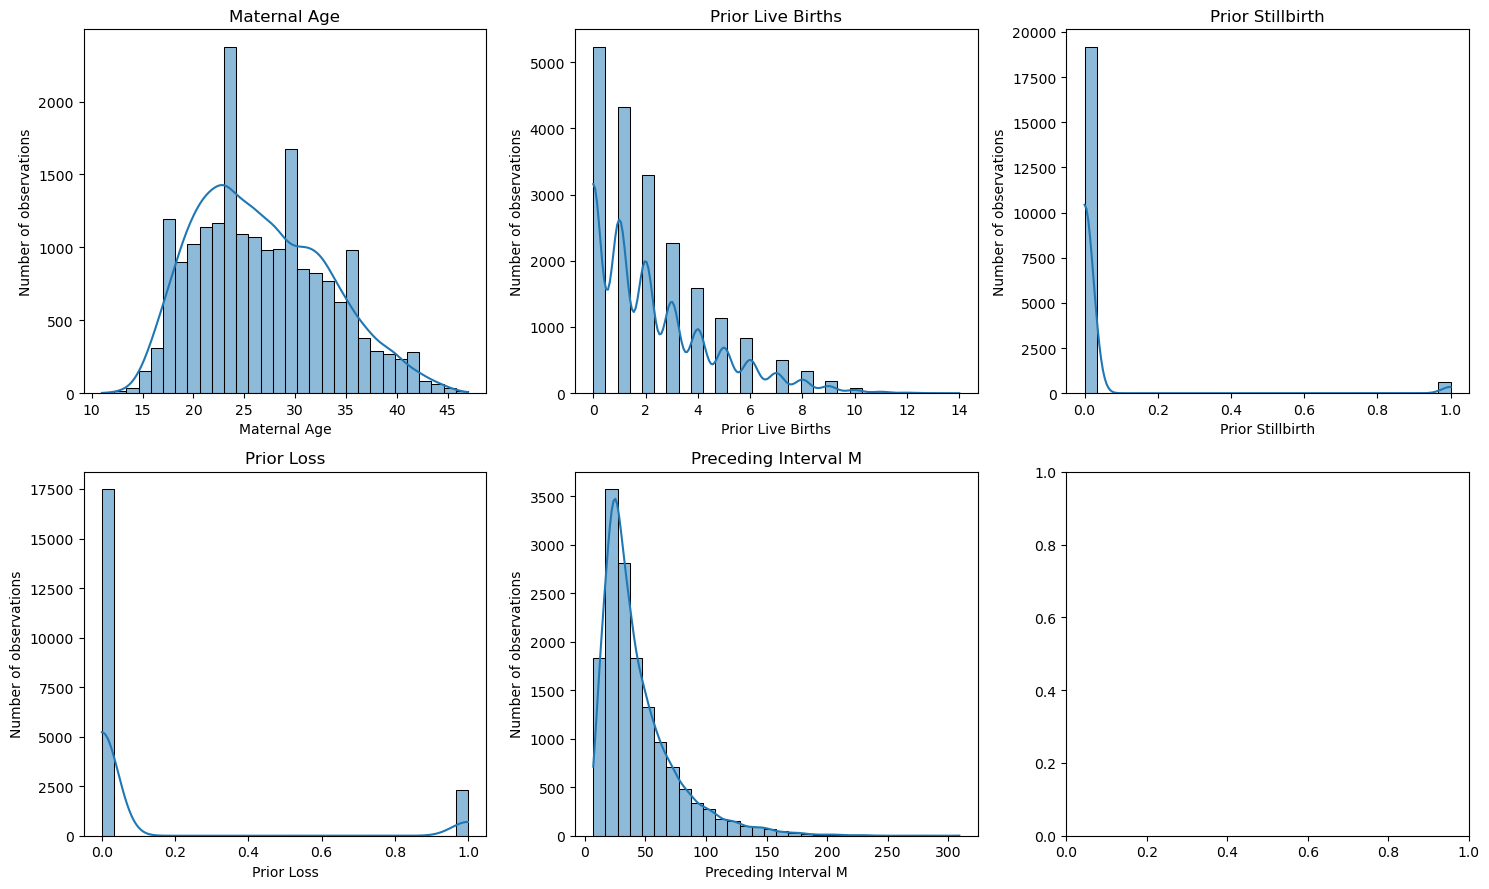

In [ ]:
# histograms for numerical predictors
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for column, ax in zip(numeric_predictors, axes.flat):
    sns.histplot(
        data=df,
        x=column,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of observations")

plt.tight_layout()
plt.show()

The categorical variables frequency deistribution

In [28]:
categorical_predictors = [
    "education",
    "wealth_quintile",
    "residence",
    "multiple",
    "region",
    "told_high_bp"
]

In [ ]:
education_counts = df["education"].value_counts(dropna=False)
print(education_counts)


education
Primary         7013
Secondary       5604
No education    4544
Higher          2661
Name: count, dtype: int64


In [30]:
# Function to calculate category counts and weighted percentages
def weighted_distribution(data, column):
    summary = data.groupby(
        column,
        dropna=False
    ).agg(
        Count=(column, "size"),
        Weighted_Total=("weight", "sum")
    )
    summary["Weighted_Percentage"] = (
        summary["Weighted_Total"]
        / summary["Weighted_Total"].sum()
        * 100
    )

    return summary.round(2)

# Test the function using education
education_summary = weighted_distribution(df, "education")
display(education_summary)


,Count,Weighted_Total,Weighted_Percentage
education,,,
Higher,2661,3172.34,17.92
No education,4544,1823.08,10.30
Primary,7013,6729.34,38.01
Secondary,5604,5977.55,33.77


In [ ]:
# Categorical predictors & their summaries
categorical_predictors = [
    "education",
    "wealth_quintile",
    "residence",
    "multiple",
    "region",
    "told_high_bp"
]

# Generate frequency tables for all categorical variables
for column in categorical_predictors:
    print(f"\nDistribution of {column}")
    summary = weighted_distribution(df, column)
    display(summary)


Distribution of education


,Count,Weighted_Total,Weighted_Percentage
education,,,
Higher,2661,3172.34,17.92
No education,4544,1823.08,10.30
Primary,7013,6729.34,38.01
Secondary,5604,5977.55,33.77



Distribution of wealth_quintile


,Count,Weighted_Total,Weighted_Percentage
wealth_quintile,,,
Middle,3431,3114.49,17.59
Poorer,3373,3178.12,17.95
Poorest,6531,3973.81,22.45
Richer,3723,3590.65,20.28
Richest,2764,3845.25,21.72



Distribution of residence


,Count,Weighted_Total,Weighted_Percentage
residence,,,
Rural,13025,11079.65,62.59
Urban,6797,6622.66,37.41


... (2 outputs left out)


Distribution of region


,Count,Weighted_Total,Weighted_Percentage
region,,,
Baringo,461,261.77,1.48
Bomet,409,340.59,1.92
Bungoma,448,589.65,3.33
Busia,438,342.05,1.93
Elgeyo-Marakwet,397,163.18,0.92
Embu,271,175.19,0.99
Garissa,594,245.75,1.39
Homa Bay,407,378.74,2.14
Isiolo,474,97.18,0.55



Distribution of told_high_bp


,Count,Weighted_Total,Weighted_Percentage
told_high_bp,,,
0.0,9655,8364.45,47.25
1.0,784,815.79,4.61
NaN,9383,8522.07,48.14


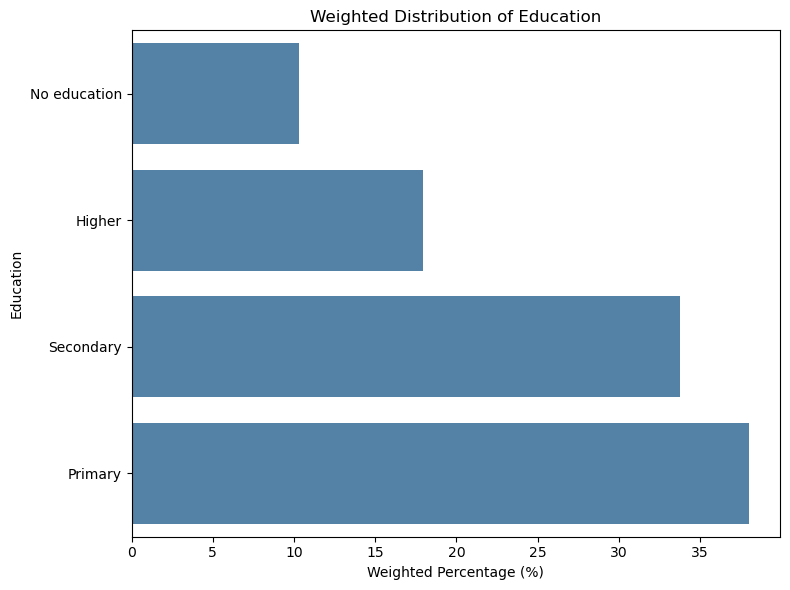

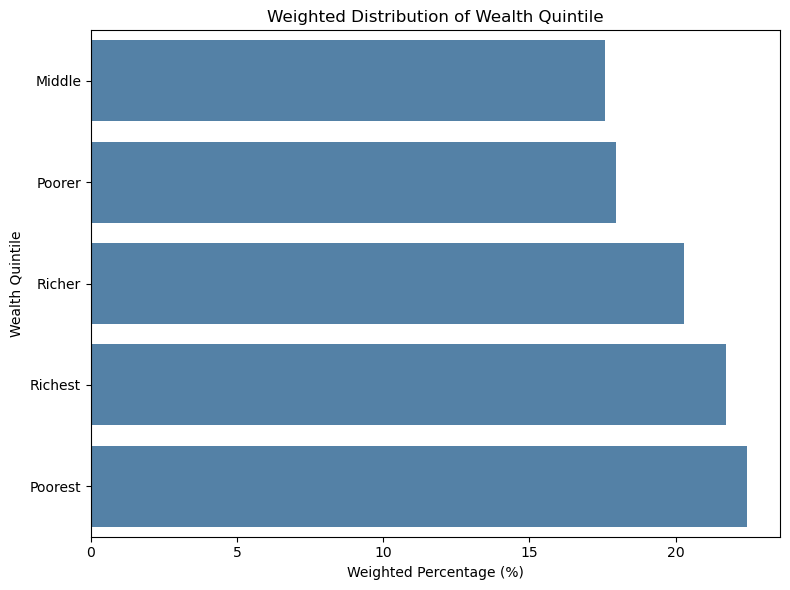

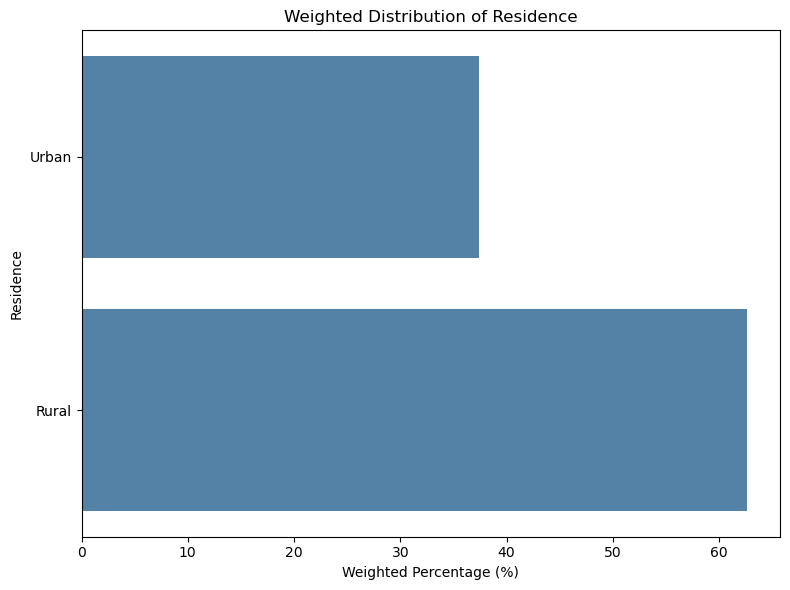

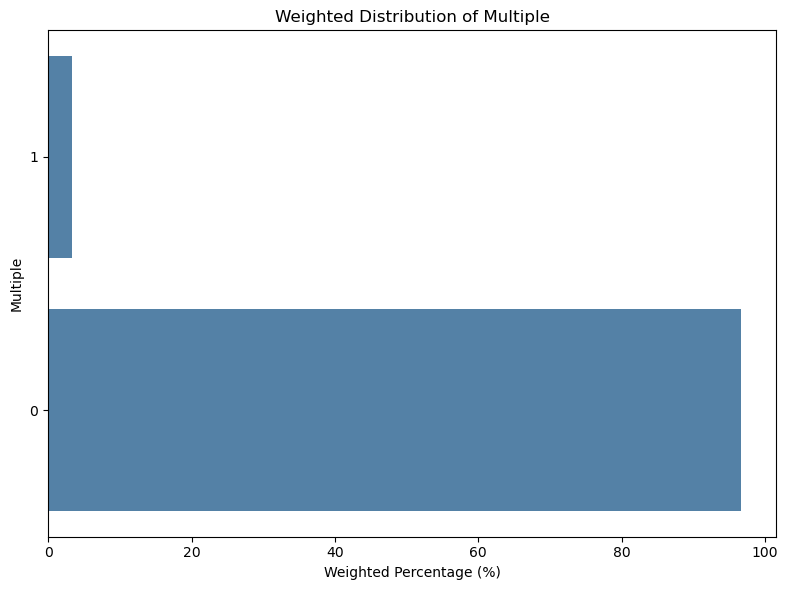

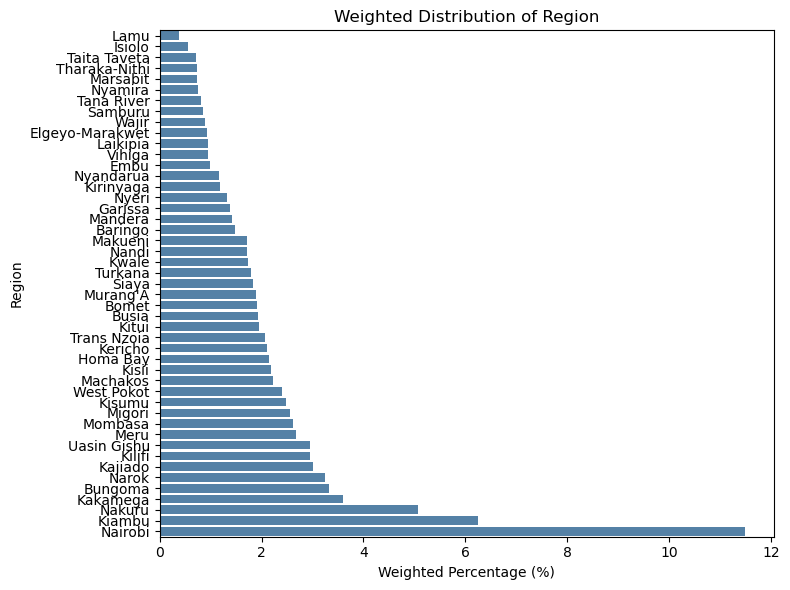

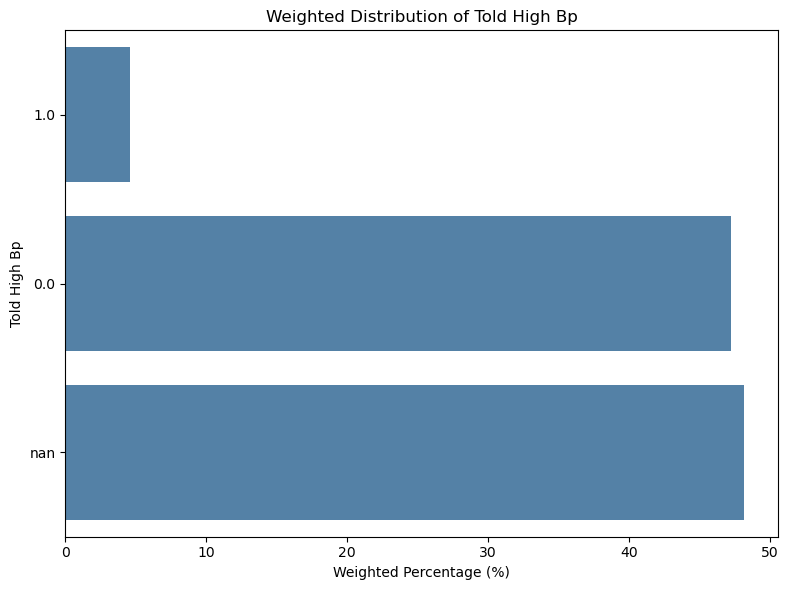

In [33]:
# Plot weighted distributions of categorical variables
for column in categorical_predictors:
    summary = weighted_distribution(df, column)
    summary = summary.sort_values("Weighted_Percentage",ascending=True)

    plt.figure(figsize=(8, 6))
    sns.barplot(x=summary["Weighted_Percentage"],y=summary.index.astype(str),color="steelblue")

    plt.title(f"Weighted Distribution of {column.replace('_', ' ').title()}")
    plt.xlabel("Weighted Percentage (%)")
    plt.ylabel(column.replace("_", " ").title())
    plt.tight_layout()
    plt.show()


primary education represented the largest weighted share of the cohort (38.01%), followed by secondary education (33.77%). The wealth distribution was relatively balanced across the five quintiles, with the poorest category accounting for the largest weighted share (22.45%). Rural residents represented 62.59% of the weighted population, compared with 37.41% from urban areas.

Most pregnancies were singleton pregnancies (96.71%), while multiple pregnancies accounted for 3.29%. The dataset included observations from all 47 Kenyan counties, although weighted representation varied geographically, with Nairobi accounting for the largest share (11.48%).

### Weighted target rates by predictor category

In [34]:
def weighted_target_rate(data, column):

    # Create a temporary copy
    temp = data[[column, target, "weight"]].copy()

    # Retain missing predictor values as a separate category
    temp[column] = temp[column].astype("object").where(
        temp[column].notna(), "Missing"
    )

    # Group observations by predictor category
    summary = temp.groupby(column, dropna=False).apply(
        lambda group: pd.Series({
            "Count": len(group),
            "Deaths": (group[target] == 1).sum(),
            "Weighted_Total": group["weight"].sum(),
            "Weighted_Deaths": (
                group[target] * group["weight"]
            ).sum(),
            "Weighted_Target_Rate": (
                group[target] * group["weight"]
            ).sum() / group["weight"].sum() * 100
        }),
        include_groups=False
    )

    return summary.round(2)


In [36]:
# Categorise maternal age
df["maternal_age_group"] = pd.cut(
    df["maternal_age"],
    bins=[0, 17, 24, 34, 100],
    labels=[
        "Under 18",
        "18-24",
        "25-34",
        "35+"
    ]
)

# Examine the age categories
print(df["maternal_age_group"].value_counts().sort_index())

maternal_age_group
Under 18    1032
18-24       7291
25-34       8871
35+         2628
Name: count, dtype: int64


In [37]:
age_results = weighted_target_rate(
    df,
    "maternal_age_group"
)

display(age_results)

,Count,Deaths,Weighted_Total,Weighted_Deaths,Weighted_Target_Rate
maternal_age_group,,,,,
18-24,7291.0,210.0,6785.35,181.24,2.67
25-34,8871.0,294.0,7821.96,243.46,3.11
35+,2628.0,126.0,2229.13,97.23,4.36
Under 18,1032.0,47.0,865.87,35.72,4.13


In [38]:
# Target rates by number of previous live births

live_birth_results = weighted_target_rate(
    df,
    "prior_live_births"
)

display(live_birth_results)

,Count,Deaths,Weighted_Total,Weighted_Deaths,Weighted_Target_Rate
prior_live_births,,,,,
0,5232.0,184.0,5265.86,161.84,3.07
1,4320.0,136.0,4205.50,133.29,3.17
2,3290.0,89.0,3112.01,76.22,2.45
3,2275.0,80.0,1933.83,62.55,3.23
4,1592.0,58.0,1236.58,41.42,3.35
5,1134.0,40.0,769.36,27.07,3.52
6,829.0,32.0,531.82,19.93,3.75
7,502.0,21.0,284.00,9.54,3.36
8,338.0,17.0,186.97,8.31,4.45


In [39]:
# Target rates by previous stillbirth history

stillbirth_results = weighted_target_rate(
    df,
    "prior_stillbirth"
)

display(stillbirth_results)

,Count,Deaths,Weighted_Total,Weighted_Deaths,Weighted_Target_Rate
prior_stillbirth,,,,,
0,19181.0,609.0,17229.93,505.17,2.93
1,641.0,68.0,472.38,52.48,11.11


In [40]:
# Target rates by previous pregnancy loss

loss_results = weighted_target_rate(
    df,
    "prior_loss"
)

display(loss_results)

,Count,Deaths,Weighted_Total,Weighted_Deaths,Weighted_Target_Rate
prior_loss,,,,,
0,17490.0,549.0,15694.27,458.69,2.92
1,2332.0,128.0,2008.04,98.96,4.93


In [41]:
# Categorise preceding birth intervals

df["interval_group"] = pd.cut(
    df["preceding_interval_m"],
    bins=[0, 23, 35, 59, float("inf")],
    labels=[
        "Under 24 months",
        "24-35 months",
        "36-59 months",
        "60+ months"
    ]
)

# Check the distribution
print(df["interval_group"].value_counts(dropna=False))

interval_group
NaN                4966
36-59 months       3939
24-35 months       3873
Under 24 months    3807
60+ months         3237
Name: count, dtype: int64


In [42]:
# Weighted target rates by preceding birth interval

interval_results = weighted_target_rate(
    df,
    "interval_group"
)

display(interval_results)

,Count,Deaths,Weighted_Total,Weighted_Deaths,Weighted_Target_Rate
interval_group,,,,,
24-35 months,3873.0,97.0,2914.81,78.08,2.68
36-59 months,3939.0,113.0,3583.81,87.52,2.44
60+ months,3237.0,123.0,3374.36,125.78,3.73
Missing,4966.0,172.0,5018.65,150.47,3.00
Under 24 months,3807.0,172.0,2810.67,115.79,4.12


In [43]:
# List of categorical predictors

categorical_predictors = [
    "education",
    "wealth_quintile",
    "residence",
    "multiple"
]

# Calculate weighted target rates

categorical_results = {}

for column in categorical_predictors:

    print(f"\nWeighted target rate by {column}")

    results = weighted_target_rate(df, column)

    categorical_results[column] = results

    display(results)



Weighted target rate by education


,Count,Deaths,Weighted_Total,Weighted_Deaths,Weighted_Target_Rate
education,,,,,
Higher,2661.0,72.0,3172.34,84.20,2.65
No education,4544.0,166.0,1823.08,64.59,3.54
Primary,7013.0,268.0,6729.34,231.25,3.44
Secondary,5604.0,171.0,5977.55,177.61,2.97



Weighted target rate by wealth_quintile


,Count,Deaths,Weighted_Total,Weighted_Deaths,Weighted_Target_Rate
wealth_quintile,,,,,
Middle,3431.0,115.0,3114.49,106.42,3.42
Poorer,3373.0,106.0,3178.12,85.80,2.70
Poorest,6531.0,227.0,3973.81,128.67,3.24
Richer,3723.0,134.0,3590.65,124.78,3.48
Richest,2764.0,95.0,3845.25,111.97,2.91



Weighted target rate by residence


,Count,Deaths,Weighted_Total,Weighted_Deaths,Weighted_Target_Rate
residence,,,,,
Rural,13025.0,426.0,11079.65,339.90,3.07
Urban,6797.0,251.0,6622.66,217.75,3.29



Weighted target rate by multiple


,Count,Deaths,Weighted_Total,Weighted_Deaths,Weighted_Target_Rate
multiple,,,,,
0,19164.0,589.0,17120.42,484.83,2.83
1,658.0,88.0,581.88,72.82,12.51


In [44]:
# Weighted target rates by region
region_results = weighted_target_rate(
    df,
    "region"
)

# Display highest rates first
region_results = region_results.sort_values(
    by="Weighted_Target_Rate",
    ascending=False
)

display(region_results)

,Count,Deaths,Weighted_Total,Weighted_Deaths,Weighted_Target_Rate
region,,,,,
Wajir,724.0,56.0,157.78,11.96,7.58
Mombasa,366.0,21.0,462.99,26.57,5.74
Siaya,401.0,20.0,323.27,17.47,5.40
Murang'A,273.0,14.0,336.36,17.19,5.11
Kisumu,431.0,19.0,438.09,20.82,4.75
Baringo,461.0,19.0,261.77,12.11,4.63
Kilifi,396.0,19.0,524.66,23.79,4.53
Uasin Gishu,397.0,15.0,521.38,23.54,4.51
Busia,438.0,20.0,342.05,14.45,4.23


In [45]:
# Weighted target rates by self-reported high blood pressure
bp_results = weighted_target_rate(
    df,
    "told_high_bp"
)

display(bp_results)

,Count,Deaths,Weighted_Total,Weighted_Deaths,Weighted_Target_Rate
told_high_bp,,,,,
0.0,9655.0,313.0,8364.45,249.41,2.98
1.0,784.0,53.0,815.79,46.10,5.65
Missing,9383.0,311.0,8522.07,262.14,3.08


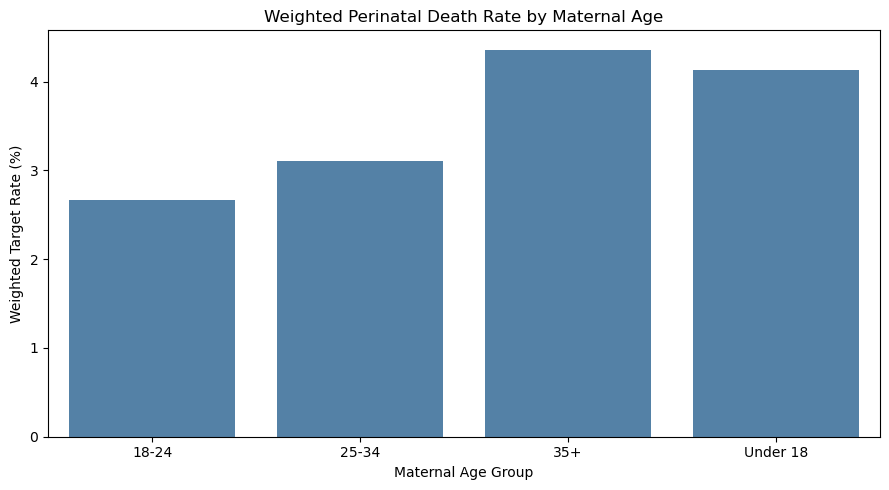

In [46]:
# Plot weighted target rates by maternal age

plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_results.reset_index(),
    x="maternal_age_group",
    y="Weighted_Target_Rate",
    color="steelblue"
)

plt.title("Weighted Perinatal Death Rate by Maternal Age")
plt.xlabel("Maternal Age Group")
plt.ylabel("Weighted Target Rate (%)")

plt.tight_layout()
plt.show()
